# Phase 2 | Probability and probability distributions

**Track C, NACC teaching subset.** Among participants with normal cognition, how does the mean number of correct animal names in 60 seconds differ per 0.1 mm greater left inferior parietal cortical thickness, after accounting for age, sex, and years of education? In this phase, we use probabilities to describe the cognitive groups and examine the unadjusted relationship between score and thickness among participants with normal cognition.

The notebook reads the linked Phase 1 table. To recreate it, place the course CSVs in the data folder and run `python3 -m src.build_dataset` from the project root. The cells use the same analysis functions as the report.


In [1]:
import os
import sys
from io import BytesIO
from pathlib import Path

from IPython.display import Image, Markdown, display

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
os.chdir(root)
sys.path.insert(0, str(root))

from src import phase2_binomial_count as counts
from src import phase2_covariance as paired
from src import phase2_distributions as dist
from src import phase2_event_probabilities as events
from src import phase2_independence_bayes as comparison
from src.phase2_samples import load_phase2_samples
from src.phase1_figures import GRAYSCALE, left_thickness, plt


def show_table(headers, rows):
    def line(columns):
        return "| " + " | ".join(map(str, columns)) + " |"

    display(Markdown("\n".join([line(headers), line(["---"] * len(headers)),
                                *(line(row) for row in rows)])))


def show_figure(draw, *args, **kwargs):
    with plt.rc_context({
        "font.family": "DejaVu Sans",
        "font.size": 10,
        "axes.labelcolor": GRAYSCALE.ink,
        "axes.labelpad": 9,
    }):
        figure = draw(*args, **kwargs)
        with BytesIO() as buffer:
            figure.savefig(buffer, format="png", dpi=120)
            display(Image(data=buffer.getvalue()))
        plt.close(figure)


def probability_cells(entry):
    return (f"{entry['numerator']} / {entry['denominator']}",
            f"{entry['probability']:.2%}")

labels = {'event_sample': 'Usable status and MRI thickness',
 'normal_group': 'Normal cognition',
 'paired_sample': 'Usable score and thickness, normal cognition',
 'sample_header': ['Sample', 'Participants'],
 'mri_summary_header': ['Thickness grouping', 'Value'],
 'cutoff': 'Pooled median (mm)',
 'ties': 'Equal to the median',
 'event_header': ['UDS status', 'At or above median', 'Below median', 'Total'],
 'statuses': ['Normal cognition', 'Other statuses', 'Total'],
 'prob_header': ['Event', 'Count / reference group', 'Probability'],
 'metric_header': ['Quantity', 'Value'],
 'conditional_gap': 'Difference between conditional rates (percentage points)',
 'joint_gap': 'Observed minus independence benchmark (percentage points)',
 'expected_cell': 'Expected common-cell count under independence',
 'binomial_header': ['Quantity', 'With replacement', 'Without replacement'],
 'mean': 'Mean',
 'variance': 'Variance',
 'median': 'Median',
 'distribution_header': ['Statistic', 'Animal-naming score', 'Left thickness (mm)'],
 'range': 'Range',
 'quartiles': 'Q1 / Q3',
 'empirical_var': 'Empirical variance',
 'sample_var': 'Sample variance',
 'skewness': 'Empirical skewness',
 'flagged': 'Flagged below / above fences',
 'normal_header': ['Percentile', 'Observed (mm)', 'Fitted normal (mm)'],
 'covariance_header': ['Covariance', 'mm × correct responses', 'Denominator'],
 'covariance_methods': ['Sample', 'Empirical']}

## 1. Participants and analysis samples

We linked each person's UDS and MRI records using `NACCID`. Each file contains one supplied record per person, and the build checks for missing or repeated IDs. The clinical visit date and number, scan date, and time between measurements are unknown. For the paired analysis, we use participants with normal cognition who have both a usable score and a usable thickness measurement.


In [2]:
samples, flow = load_phase2_samples()
event_rows = samples[events.SAMPLE_NAME]
paired_rows = samples[dist.SAMPLE_NAME]
sample_table = [
    (labels["event_sample"], len(event_rows)),
    (labels["normal_group"], flow["matched_normal_cognition_before_eligibility"]),
    (labels["paired_sample"], len(paired_rows)),
]
show_table(labels["sample_header"], sample_table)

| Sample | Participants |
| --- | --- |
| Usable status and MRI thickness | 1237 |
| Normal cognition | 847 |
| Usable score and thickness, normal cognition | 843 |

## 2. Cross-modal events

We define $A$ as normal cognition, recorded in UDS as `NACCUDSD = 1`. The MRI event $B$ includes thickness measurements at or above the median of all eligible participants. Values exactly equal to this descriptive cutoff also belong to $B$. Each probability uses the numerator and denominator shown in its row. The share with normal cognition is higher in the at-or-above-median group.


In [3]:
e = events.summarize_events(event_rows)
table = e["contingency_table"]
show_table(labels["mri_summary_header"], [
    (labels["cutoff"], f"{e['events']['B']['median_mm']:.3f}"),
    (labels["ties"], e["events"]["B"]["equal_to_median"]),
])
show_table(labels["event_header"], [
    (label, table[key]["B"], table[key]["not_B"], table[key]["total"])
    for key, label in zip(("A", "not_A", "total"), labels["statuses"])
])
show_table(labels["prob_header"], [
    (formula, *probability_cells(e[section][key]))
    for section, keys in (
        ("marginal_probabilities", [
            ("A", "$A$"), ("not_A", "$A^c$"), ("B", "$B$"), ("not_B", "$B^c$"),
        ]),
        ("joint_probabilities", [
            ("A_and_B", r"$A\cap B$"), ("A_and_not_B", r"$A\cap B^c$"),
            ("not_A_and_B", r"$A^c\cap B$"), ("not_A_and_not_B", r"$A^c\cap B^c$"),
        ]),
        ("conditional_probabilities", [
            ("A_given_B", r"$A\mid B$"), ("A_given_not_B", r"$A\mid B^c$"),
        ]),
    )
    for key, formula in keys
])
show_table(labels["metric_header"], [
    (labels["conditional_gap"], f"{e['conditional_difference_percentage_points']:.2f}"),
])

| Thickness grouping | Value |
| --- | --- |
| Pooled median (mm) | 2.319 |
| Equal to the median | 5 |

| UDS status | At or above median | Below median | Total |
| --- | --- | --- | --- |
| Normal cognition | 488 | 359 | 847 |
| Other statuses | 134 | 256 | 390 |
| Total | 622 | 615 | 1237 |

| Event | Count / reference group | Probability |
| --- | --- | --- |
| $A$ | 847 / 1237 | 68.47% |
| $A^c$ | 390 / 1237 | 31.53% |
| $B$ | 622 / 1237 | 50.28% |
| $B^c$ | 615 / 1237 | 49.72% |
| $A\cap B$ | 488 / 1237 | 39.45% |
| $A\cap B^c$ | 359 / 1237 | 29.02% |
| $A^c\cap B$ | 134 / 1237 | 10.83% |
| $A^c\cap B^c$ | 256 / 1237 | 20.70% |
| $A\mid B$ | 488 / 622 | 78.46% |
| $A\mid B^c$ | 359 / 615 | 58.37% |

| Quantity | Value |
| --- | --- |
| Difference between conditional rates (percentage points) | 20.08 |

## 3. Independence and Bayes' rule

If the events were independent with these same margins, $P(A)P(B)$ would give their joint probability. In the observed table, $P(A\cap B)$ is higher. We then use Bayes' rule, $P(B\mid A)P(A)/P(B)$, to update the probability of normal cognition, $P(A)$, when a person's thickness group is known. The calculation below checks that this result equals direct counting exactly. These probabilities describe the supplied subset.


In [4]:
checks = comparison.compare_probabilities(e)
independence = checks["independence"]
bayes = checks["bayes"]
show_table(labels["metric_header"], [
    (r"$P(A\cap B)$", f"{independence['observed_joint_A_and_B']['probability']:.2%}"),
    ("$P(A)P(B)$", f"{independence['joint_if_independent']['probability']:.2%}"),
    (labels["joint_gap"], f"{independence['observed_minus_expected_percentage_points']:.2f}"),
    (labels["expected_cell"], f"{independence['expected_count_if_independent']:.1f}"),
])
show_table(labels["prob_header"], [
    ("$P(A)$", *probability_cells(bayes["prior_A"])),
    (r"$P(B\mid A)$", *probability_cells(bayes["likelihood_B_given_A"])),
    ("$P(B)$", *probability_cells(bayes["evidence_B"])),
    (r"$P(A\mid B)$", *probability_cells(bayes["posterior_A_given_B_direct"])),
])
assert bayes["matches_direct_exactly"]

| Quantity | Value |
| --- | --- |
| $P(A\cap B)$ | 39.45% |
| $P(A)P(B)$ | 34.43% |
| Observed minus independence benchmark (percentage points) | 5.02 |
| Expected common-cell count under independence | 425.9 |

| Event | Count / reference group | Probability |
| --- | --- | --- |
| $P(A)$ | 847 / 1237 | 68.47% |
| $P(B\mid A)$ | 488 / 847 | 57.62% |
| $P(B)$ | 622 / 1237 | 50.28% |
| $P(A\mid B)$ | 488 / 622 | 78.46% |

## 4. A binomial count

Suppose we draw 20 times from the eligible records, giving each person an equal chance of selection. Let $Z$ count the draws that select someone with normal cognition. With replacement, the draws are independent and each has the same success probability. Without replacement, each draw depends on who remains and the count follows a hypergeometric distribution. For this example, we calculate the probability of at least 15 successes, or three quarters of the draws. The two models give similar probabilities for this event.


In [5]:
model = counts.summarize_count(len(event_rows), table["A"]["total"])
models = [model[key] for key in ("with_replacement", "without_replacement")]
show_table(labels["binomial_header"], [
    (labels["mean"], *(f"{item['expected_count']:.2f}" for item in models)),
    (labels["variance"], *(f"{item['variance']:.2f}" for item in models)),
    (r"$P(Z \geq " + str(model["tail_minimum"]) + ")$",
     *(f"{item['probability_at_least_tail_minimum']:.2%}" for item in models)),
])

| Quantity | With replacement | Without replacement |
| --- | --- | --- |
| Mean | 13.69 | 13.69 |
| Variance | 4.32 | 4.25 |
| $P(Z \geq 15)$ | 35.95% | 35.80% |

## 5. Empirical distributions and a normal reference

We summarize score and thickness for the same paired participants. Empirical and sample variances divide the sum of squared distances from the mean by $n$ and $n-1$, respectively. We flag values outside the 1.5-IQR fences for review and include them in the analysis. The score plot has one bar per integer score, and each thickness histogram bin spans 0.05 mm.

In the Q-Q plot, we compare ordered thickness measurements with a normal reference fitted to their empirical mean and standard deviation. The plotting positions are $(i-0.5)/n$. The center is closer to the reference. In the lower tail, the observed first percentile is below the normal reference.


| Statistic | Animal-naming score | Left thickness (mm) |
| --- | --- | --- |
| Range | 7 – 43 | 1.474 – 2.666 |
| Mean | 22.32 | 2.336 |
| Median | 22 | 2.338 |
| Q1 / Q3 | 18 / 26 | 2.269 / 2.4175 |
| Empirical variance | 29.504 | 0.014747 |
| Sample variance | 29.539 | 0.014764 |
| Empirical skewness | 0.36 | -0.95 |
| Flagged below / above fences | 0 / 4 | 12 / 3 |

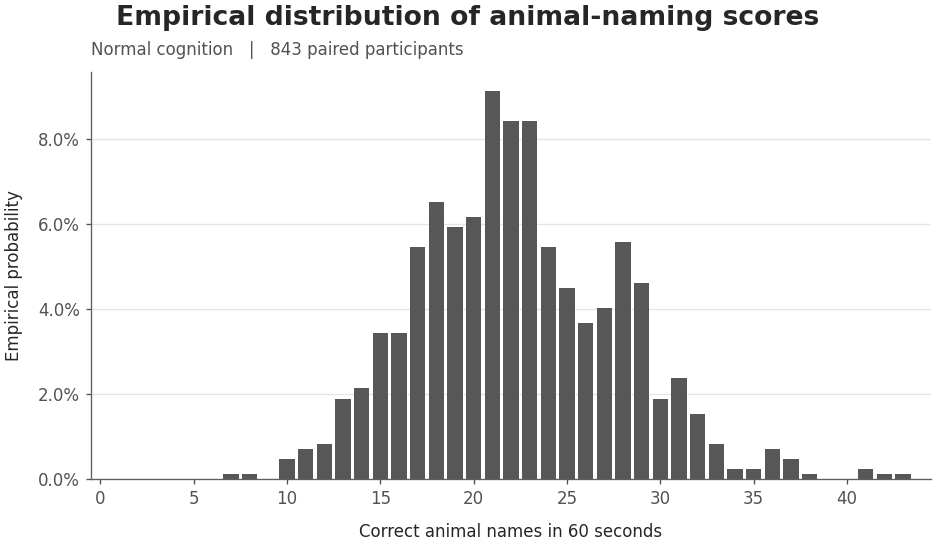

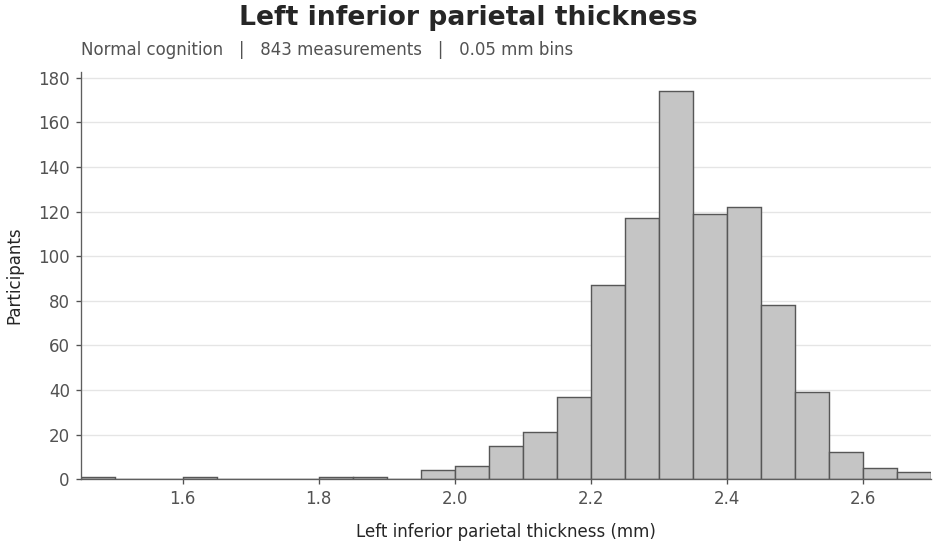

| Percentile | Observed (mm) | Fitted normal (mm) |
| --- | --- | --- |
| 1 | 2.003 | 2.054 |
| 5 | 2.135 | 2.137 |
| 50 | 2.338 | 2.336 |
| 95 | 2.511 | 2.536 |
| 99 | 2.590 | 2.619 |

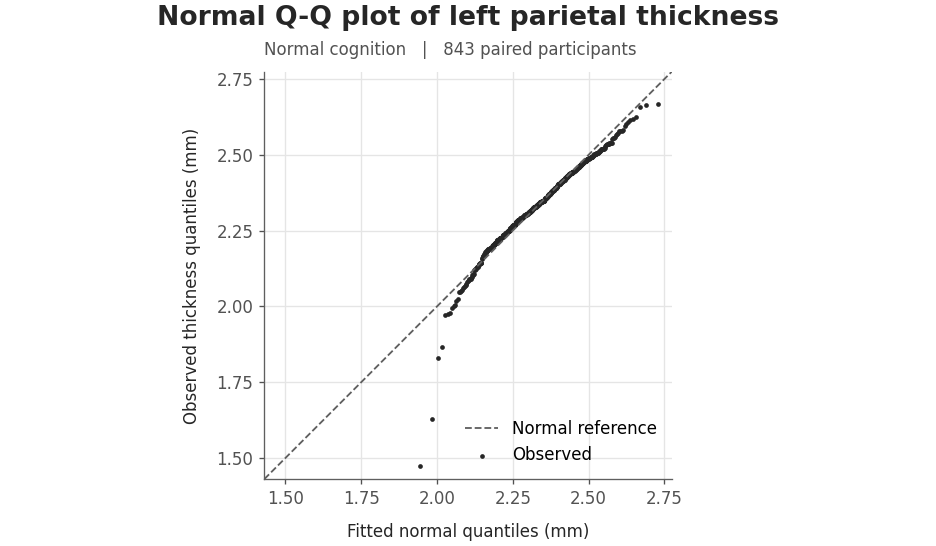

In [6]:
distribution = dist.summarize_distributions(paired_rows)
thickness = [row[dist.LEFT_THICKNESS] for row in paired_rows]
scores = [row[dist.SCORE] for row in paired_rows]
summary = [distribution["summaries"][key] for key in (dist.SCORE, dist.LEFT_THICKNESS)]
show_table(labels["distribution_header"], [
    (labels["range"], *(f"{s['minimum']:g} – {s['maximum']:g}" for s in summary)),
    (labels["mean"], f"{summary[0]['mean']:.2f}", f"{summary[1]['mean']:.3f}"),
    (labels["median"], *(f"{s['median']:g}" for s in summary)),
    (labels["quartiles"], *(f"{s['q1']:g} / {s['q3']:g}" for s in summary)),
    (labels["empirical_var"], f"{summary[0]['empirical_variance']:.3f}",
     f"{summary[1]['empirical_variance']:.6f}"),
    (labels["sample_var"], f"{summary[0]['sample_variance']:.3f}",
     f"{summary[1]['sample_variance']:.6f}"),
    (labels["skewness"], *(f"{s['empirical_skewness']:.2f}" for s in summary)),
    (labels["flagged"], *(f"{s['iqr_review']['below']} / {s['iqr_review']['above']}" for s in summary)),
])
show_figure(dist.animal_score_pmf, distribution["animal_score_frequency"])
show_figure(left_thickness, thickness, palette=GRAYSCALE)
reference = distribution["thickness_normal_reference"]
show_table(labels["normal_header"], [
    (item["percentile"], f"{item['empirical_mm']:.3f}", f"{item['fitted_normal_mm']:.3f}")
    for item in reference["quantile_checks"]
])
show_figure(dist.thickness_normal_qq, thickness, reference)

## 6. Paired score and thickness

Each point represents one person. Transparency helps show where measurements overlap. The positive covariance summarizes the direction of the centered cross-products, with units of mm times correct responses. The scatter also shows wide variation in scores among people with similar thicknesses.


| Covariance | mm × correct responses | Denominator |
| --- | --- | --- |
| Sample | 0.010466 | 842 |
| Empirical | 0.010453 | 843 |

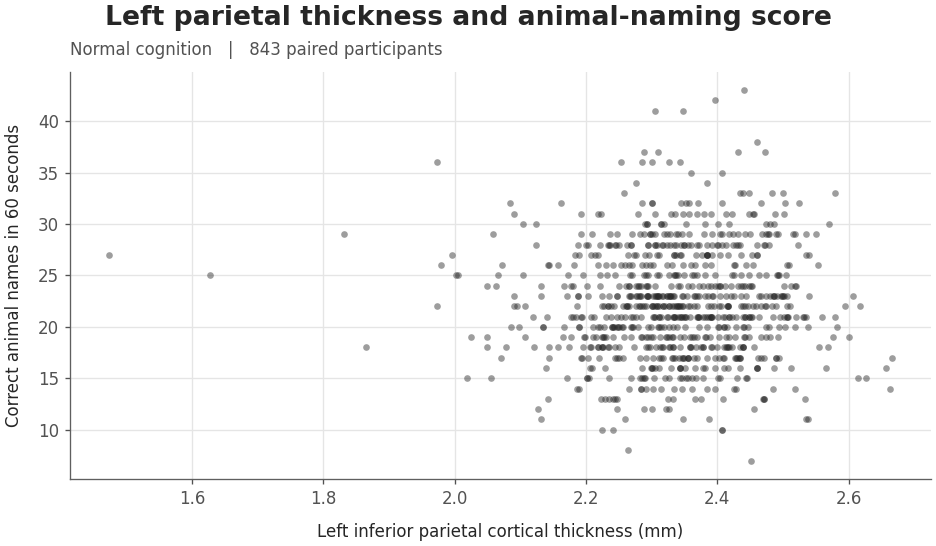

In [7]:
association = paired.summarize_covariance(thickness, scores)
covariance = association["covariance"]
show_table(labels["covariance_header"], [
    (label, f"{covariance[key]['value']:.6f}", covariance[key]["denominator"])
    for key, label in zip(("sample", "empirical"), labels["covariance_methods"])
])
show_figure(paired.paired_scatter, thickness, scores)

## Interpretation and sources

These results describe the NACC teaching subset under the rules for entry into each analysis sample. The sampling frame and the time between the two measurements are unknown. In Phase 4, we will estimate the adjusted difference in score per 0.1 mm of thickness.

[Course guide, Phase 2](../docs/amarpr.pdf#page=8) · [Project card and variable definitions](../PROJECT_CARD.md) · [English Phase 2 report](../reports/phase2.pdf)
